In [ ]:
import pandas as pd
import numpy as np
import numpy_financial as npf
import psycopg2
import sqlalchemy
import pandas.io.sql as sqlio 
from datetime import datetime
import xlrd 
import matplotlib 
import matplotlib.pyplot as plt 
import unidecode
from dateutil.relativedelta import relativedelta

In [14]:
Modelo = pd.read_excel(r'C:\Users\juan.valladares\Documents\Planificación\Modelo_Carretera_Financiero.xlsx')
Modelo

,Año,CAPEX,OPEX,Ingresos por Peaje,Flujo Neto
0,0,-2000000,0,0,-2000000
1,1,0,500000,1000000,500000
2,2,0,500000,1000000,500000
3,3,0,500000,1000000,500000
4,4,0,500000,1000000,500000
5,5,0,500000,1000000,500000


In [15]:
# Flujos de Caja
flujos = np.array([-2000000, 500000, 500000, 500000, 500000, 500000])
tasa_descuento = 0.10  

In [16]:
# VAN 
van = sum([f / (1 + tasa_descuento) ** i for i, f in enumerate(flujos)])

In [17]:
# TIR con Función de Newton-Raphson (iterativo)

def calc_tir(cash_flows, guess=0.1, max_iter=1000, tol=1e-6):
    r = guess  # Tasa inicial
    for _ in range(max_iter):
        f_val = sum([cf / (1 + r) ** i for i, cf in enumerate(cash_flows)]) # Valor de la función (VAN) en la tasa actual
        f_der = sum([-i * cf / (1 + r) ** (i + 1) for i, cf in enumerate(cash_flows)]) # Derivada de la función con respecto a r
        if abs(f_val) < tol:
            return r  # Criterio de parada cuando el VAN es cercano a 0
        
        # Actualización por Newton-Raphson
        new_r = r - f_val / f_der 
        r = new_r
        
    return r  # Si no converge, devolver la última estimación

In [ ]:
# Ejecución de la Funcion para obtener la TIR
tir = calc_tir(flujos) 

In [23]:
# ROI 
roi = (sum(flujos[1:]) / abs(flujos[0])) * 100

In [28]:
# Resultados Generales  
print(f"VAN (manual): ${van:,.2f}")
print(f"TIR (manual): {tir:.2%}") 
print(f"ROI (manual): {roi:.2f}%")

VAN (manual): $-104,606.62
TIR (manual): 7.93%
ROI (manual): 125.00%


In [ ]:
# VAN usando la TIR (debería ser ≈ 0)
van_en_tir = sum([f / (1 + tir) ** i for i, f in enumerate(flujos)])
print(f"VAN evaluado en TIR: ${van_en_tir:,.2f}")

VAN evaluado en TIR: $0.00


In [ ]:
# Resultados Finales para Comprobación 
print(f"VAN (manual): ${van_en_tir:,.2f}")
print(f"TIR (manual): {tir:.2%}") 
print(f"ROI (manual): {roi:.2f}%")  

VAN (manual): $0.00
TIR (manual): 7.93%
ROI (manual): 125.00%


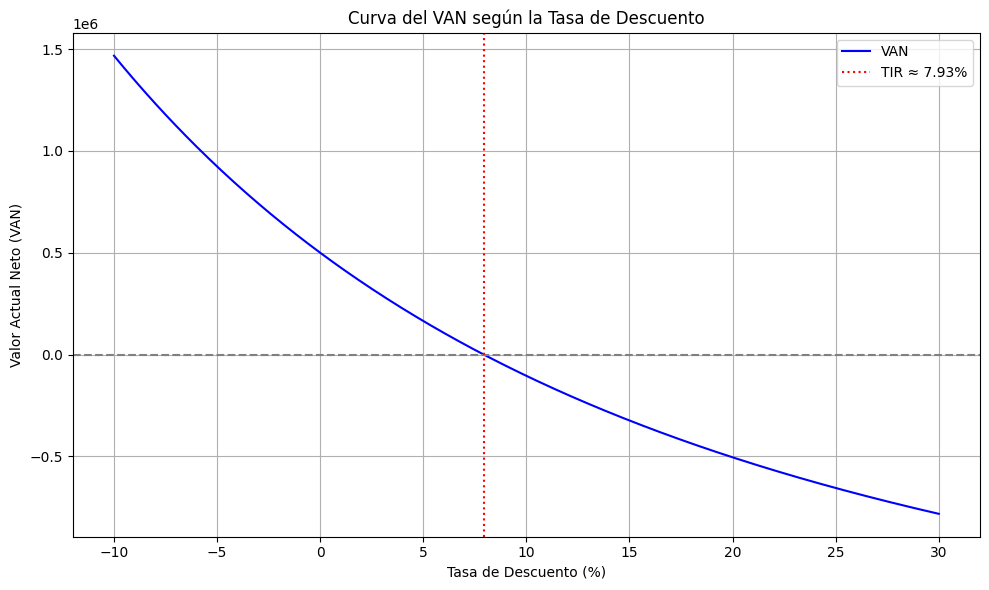

In [ ]:
# Rangos de tasas: desde -10% hasta 30%
tasas = np.linspace(-0.1, 0.3, 400)

# Calcular VAN para cada tasa
van_values = [npf.npv(r, flujos) for r in tasas]

# Graficar
plt.figure(figsize=(10, 6))
plt.plot(tasas * 100, van_values, label="VAN", color='blue')
plt.axhline(0, color='gray', linestyle='--')
plt.axvline(x=7.93, color='red', linestyle=':', label='TIR ≈ 7.93%')

plt.title("Curva del VAN según la Tasa de Descuento")
plt.xlabel("Tasa de Descuento (%)")
plt.ylabel("Valor Actual Neto (VAN)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Convergencia de la TIR usando Newton-Raphson ###

In [ ]:
# Función que imprime cada Iteración #

def calc_tir_verbose(cash_flows, guess=0.1, max_iter=1000, tol=1e-6):
    r = guess 
    print(f"{'Iteración':>10} | {'Tasa (r)':>10} | {'VAN':>15} | {'Derivada':>15}")
    print("-" * 60)
    
    for i in range(max_iter):
        f_val = sum([cf / (1 + r) ** i for i, cf in enumerate(cash_flows)])
        f_der = sum([-i * cf / (1 + r) ** (i + 1) for i, cf in enumerate(cash_flows)])
        
        print(f"{i:10} | {r:10.6f} | {f_val:15,.2f} | {f_der:15,.2f}")
        
        if abs(f_val) < tol:
            print("\n✅ Convergencia lograda.")
            return r
        
        new_r = r - f_val / f_der
        r = new_r 

    print("\n⚠️ No se logró convergencia tras máximo de iteraciones.")
    return r

In [36]:
tir_verbose = calc_tir_verbose(flujos)

 Iteración |   Tasa (r) |             VAN |        Derivada
------------------------------------------------------------
         0 |   0.100000 |     -104,606.62 |   -4,842,085.60
         1 |   0.078396 |        4,821.27 |   -5,297,291.71
         2 |   0.079307 |            9.23 |   -5,277,017.43
         3 |   0.079308 |            0.00 |   -5,276,978.55
         4 |   0.079308 |            0.00 |   -5,276,978.55

✅ Convergencia lograda.


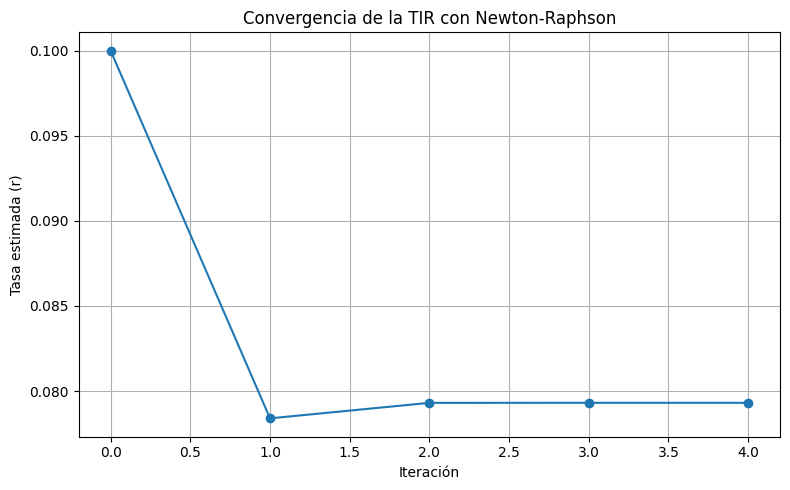

In [34]:
# Gráfico de Convergencia de la TIR 

def calc_tir_with_tracking(cash_flows, guess=0.1, max_iter=1000, tol=1e-6):
    r = guess
    history = [r]
    
    for _ in range(max_iter):
        f_val = sum([cf / (1 + r) ** i for i, cf in enumerate(cash_flows)])
        f_der = sum([-i * cf / (1 + r) ** (i + 1) for i, cf in enumerate(cash_flows)])
        
        if abs(f_val) < tol:
            break
        
        r = r - f_val / f_der
        history.append(r)
        
    return r, history

# Ejecutar y graficar
tir, iter_history = calc_tir_with_tracking(flujos)

plt.figure(figsize=(8, 5))
plt.plot(iter_history, marker='o')
plt.title("Convergencia de la TIR con Newton-Raphson")
plt.xlabel("Iteración")
plt.ylabel("Tasa estimada (r)")
plt.grid(True)
plt.tight_layout()
plt.show()


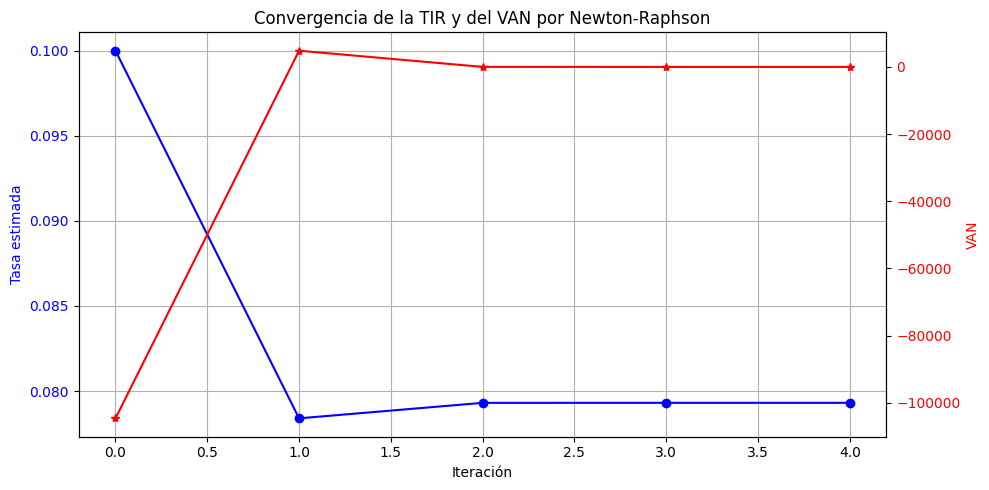

In [ ]:
# Función modificada que guarda historial de tasas y VAN
def calc_tir_with_van_tracking(cash_flows, guess=0.1, max_iter=1000, tol=1e-6):
    r = guess
    tasa_history = [r]
    van_history = []
    
    for _ in range(max_iter):
        f_val = sum([cf / (1 + r) ** i for i, cf in enumerate(cash_flows)])
        f_der = sum([-i * cf / (1 + r) ** (i + 1) for i, cf in enumerate(cash_flows)])
        
        van_history.append(f_val)  # Guardar VAN de esta iteración
        
        if abs(f_val) < tol:
            break 
        
        r = r - f_val / f_der
        tasa_history.append(r)
    
    return r, tasa_history, van_history

# Ejecutar función
tir, tasas, vans = calc_tir_with_van_tracking(flujos)

# Crear gráfico
fig, ax1 = plt.subplots(figsize=(10, 5))

# Eje 1: TIR (tasa)
ax1.plot(tasas, 'bo-', label='Tasa estimada (TIR)')
ax1.set_xlabel("Iteración")
ax1.set_ylabel("Tasa estimada", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.grid(True)

# Eje 2: VAN
ax2 = ax1.twinx()
ax2.plot(vans, 'r*-', label='VAN en cada iteración')
ax2.set_ylabel("VAN", color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Título y leyenda
plt.title("Convergencia de la TIR y del VAN por Newton-Raphson")
fig.tight_layout()
plt.show()


### METODOLOGIA ALTERNATIVA ###

In [13]:
# Flujos de caja
flujos = np.array([-2000000, 500000, 500000, 500000, 500000, 500000])
tasa_descuento = 0.10

In [ ]:
# VAN con numpy_financial
van_npf = npf.npv(tasa_descuento, flujos)
van_npf 

np.float64(-104606.61529577622)

In [ ]:
# TIR con numpy_financial
tir_npf = npf.irr(flujos)

In [18]:
# ROI manual
roi = (sum(flujos[1:]) / abs(flujos[0])) * 100

In [ ]:
# Resultados
print(f"VAN (npf): ${van_npf:,.2f}")
print(f"TIR (npf): {tir_npf:.2%}")
print(f"ROI: {roi:.2f}%")

VAN (npf): $-104,606.62
TIR (npf): 7.93%
ROI: 125.00%


### EJEMPLO MODELO FINANCIERO ###

In [1]:
# --------------------------
# 1. Parámetros del Modelo
# --------------------------

# Ingresos estimados por año
ingresos = [0, 1_000_000, 1_200_000, 1_300_000, 1_400_000, 1_500_000]

# Costos de operación y administración por año
costos_operacion = [0, 300_000, 350_000, 370_000, 400_000, 420_000]

# Costos de mantenimiento (rutinario o periódico)
mantenimiento = [0, 50_000, 50_000, 60_000, 60_000, 70_000]

# Inversión inicial (CAPEX)
capex_inicial = 2_000_000

# Años
anios = len(ingresos)

In [ ]:
# --------------------------
# 2. Flujo Neto de Caja
# --------------------------

flujo_neto = [-capex_inicial]  # Año 0

for i in range(1, anios):
    neto = ingresos[i] - costos_operacion[i] - mantenimiento[i]
    flujo_neto.append(neto)

print("Flujos netos:", flujo_neto)

Flujos netos: [-2000000, 650000, 800000, 870000, 940000, 1010000]


In [ ]:
# --------------------------
# 3. VAN (con tasa estimada)
# --------------------------

def calcular_van(flujos, tasa):
    return sum([f / (1 + tasa) ** i for i, f in enumerate(flujos)])

# Ejemplo: VAN con tasa de 10%
tasa_descuento = 0.10 
van = calcular_van(flujo_neto, tasa_descuento)
print("VAN (10%):", round(van, 2))

VAN (10%): 1174873.18


In [ ]:
# --------------------------
# 4. ROI (Retorno sobre inversión)
# --------------------------

roi = (sum(flujo_neto[1:]) - abs(flujo_neto[0])) / abs(flujo_neto[0])
print("ROI:", round(roi * 100, 2), "%") 

ROI: 113.5 %


In [ ]:
# --------------------------
# 5. TIR con Newton-Raphson
# --------------------------

def tir_newton_raphson(flujos, tasa_inicial=0.1, tol=1e-6, max_iter=100):
    tasa = tasa_inicial
    for _ in range(max_iter):
        van = calcular_van(flujos, tasa)
        van_deriv = sum([-i * f / (1 + tasa) ** (i + 1) for i, f in enumerate(flujos)])
        if abs(van_deriv) < 1e-10:
            break  # Evita divisiones por casi cero
        nueva_tasa = tasa - van / van_deriv
        if abs(nueva_tasa - tasa) < tol:
            return nueva_tasa
        tasa = nueva_tasa
    return tasa

tir = tir_newton_raphson(flujo_neto) 
print("TIR estimada:", round(tir * 100, 2), "%")

TIR estimada: 29.29 %
